# Tarea 20: Regresión Multiple, Lasso y Ridge

### Carga de Librerias y Datos

In [1]:
from locale import normalize

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data_frame = pd.read_excel('FuelConsumptionCo2.xlsx')
data_frame.sample(5)

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
127,2022,BMW,X7 xDrive40i,SUV: Standard,3.0,6,AS8,Z,12.1,9.8,11.1,25,256
192,2022,Chevrolet,Malibu,Mid-size,1.5,4,AV,X,8.2,6.6,7.5,38,175
591,2022,Lexus,LC 500,Subcompact,5.0,8,AS10,Z,15.1,9.6,12.6,22,294
321,2022,Ford,F-150 4X4 FFV,Pickup truck: Standard,3.3,6,AS10,X,12.6,10.7,11.8,24,277
300,2022,Ford,Expedition 4X4,SUV: Standard,3.5,6,AS10,X,14.8,10.6,12.9,22,304


In [27]:
data_frame.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,945.0,945.000000,945.000000,945.000000,945.000000,945.000000,945.000000,945.000000
mean,2022.0,3.201058,5.670899,12.515767,9.374603,11.102222,27.222222,259.410582
std,0.0,1.374256,1.932837,3.452369,2.290217,2.878074,7.684409,64.486225
min,2022.0,1.200000,3.000000,4.000000,3.900000,4.000000,11.000000,94.000000
25%,2022.0,2.000000,4.000000,10.200000,7.700000,9.100000,22.000000,214.000000
50%,2022.0,3.000000,6.000000,12.200000,9.200000,10.800000,26.000000,258.000000
75%,2022.0,3.800000,6.000000,14.700000,10.700000,12.900000,31.000000,301.000000
max,2022.0,8.000000,16.000000,30.300000,20.900000,26.100000,71.000000,608.000000


### Limpieza de los datos

In [8]:
# Drop categorical columns
data_cleaned = data_frame.drop(columns=['MAKE', 'MODEL', 'VEHICLECLASS', 'TRANSMISSION', 'FUELTYPE'])
data_cleaned.sample(5)
data_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 945 entries, 0 to 944
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   MODELYEAR                 945 non-null    int64  
 1   ENGINESIZE                945 non-null    float64
 2   CYLINDERS                 945 non-null    int64  
 3   FUELCONSUMPTION_CITY      945 non-null    float64
 4   FUELCONSUMPTION_HWY       945 non-null    float64
 5   FUELCONSUMPTION_COMB      945 non-null    float64
 6   FUELCONSUMPTION_COMB_MPG  945 non-null    int64  
 7   CO2EMISSIONS              945 non-null    int64  
dtypes: float64(4), int64(4)
memory usage: 59.2 KB


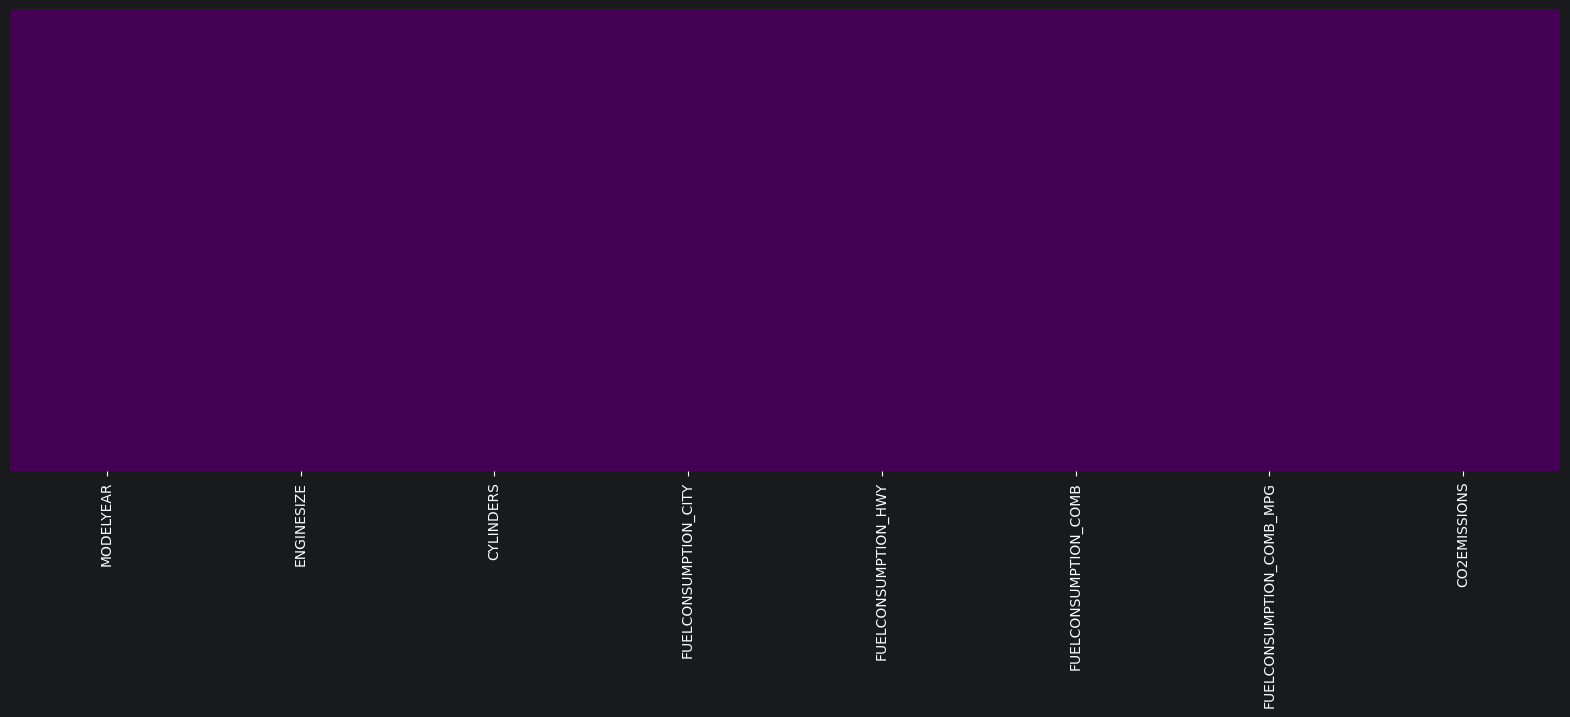

In [10]:
#Visualize if there are null values
plt.figure(figsize=(20,6))
sns.heatmap(data_cleaned.isnull(), yticklabels=False, cbar=False, cmap="viridis")
plt.show()

*NOTA*: Como se muestra en los comando describe y con la gráfica de manera visual el data set no contiene informacion nula.

### Análisis de regresion multiple

Definición de las las variables *X* como los datos sin la columna de las emeciones de co2 'CO2EMISSIONS' e *Y* como la columna 'CO2EMISSIONS'

In [14]:
x_data = data_cleaned.drop('CO2EMISSIONS', axis=1)
y_data = data_cleaned['CO2EMISSIONS']

x_data.sample(5)

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG
622,2022,3.0,6,15.1,10.9,13.2,21
530,2022,6.4,8,18.5,14.1,16.5,17
800,2022,3.0,6,13.8,10.7,12.4,23
605,2022,3.5,6,13.1,9.4,11.1,25
278,2022,2.3,4,12.1,11.4,11.8,24


In [16]:
y_data.sample(5)

416    281
296    198
898    180
605    268
783    289
Name: CO2EMISSIONS, dtype: int64

Definición de las variables de entrenamiento y prueba desde los x_data e y_data

*Nota*: se importa la librearia sklearn

In [19]:
from sklearn.model_selection import train_test_split
# in this line, test_size means the size of the data to make the test is 30% and the seed to the random number is 1
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.3, random_state=1)

#### Creacion del modelo de regresión multiple

In [20]:
from sklearn.linear_model import LinearRegression
linear_regression = LinearRegression()
linear_regression.fit(x_train, y_train)

LinearRegression()

In [22]:
# Results from the linear regression
print(f'Intercept: {linear_regression.intercept_}')
print(f'Coefficients: {linear_regression.coef_}')

Intercept: 124.05613100622469
Coefficients: [ 0.         -0.01515148  6.43036425 -1.32628678  0.52702525 14.53834062
 -1.88292508]


### Observación 1: Predicción manual de la primera observación de la base de prueba

Primero se calcula la predicción de y_predict y en la siguiente celda se calcula y_predict_manual a partir de la siguiente ecuación:

*y_manual_prediction*=124.0561+0⋅MODELYEAR+(−0.01515)⋅ENGINESIZE+6.43036⋅CYLINDERS+…

In [23]:
y_pred = linear_regression.predict(x_test)
y_pred

array([318.82062694, 322.84703822, 345.23551728, 174.78239603,
       196.73994807, 250.37345085, 240.2772048 , 332.29424162,
       327.80185548, 173.64652185, 275.75871276, 227.67606101,
       323.15858211, 264.7147751 , 175.92922152, 267.50620255,
       162.5548175 , 220.68619289, 337.80918664, 326.56057625,
       322.84703822, 339.48137878, 259.20584163, 220.68619289,
       339.76297512, 201.8255166 , 364.62108712, 334.53095579,
       286.6535063 , 137.95706661, 179.28808399, 175.92922152,
       238.60801519, 291.97541448, 312.36078823, 291.32632034,
       330.50151422, 317.77510602, 327.80185548, 218.69601311,
       302.19635808, 294.44143376, 228.58586706, 182.33789374,
       170.20435766, 247.91950372, 193.35806215, 343.30481828,
       152.91430008, 184.32703834, 291.68467823, 239.45777535,
       170.44542168, 262.19926692, 112.39018005, 312.507081  ,
       343.13766885, 335.91261837, 307.08026329, 385.77737538,
       198.41216797, 150.50258803, 186.61208853, 304.78

In [44]:
# First row from the test
first_row = x_test.iloc[0]

# Manual prediction = intercept + sum(coef_i * valor_i)
manual_prediction = linear_regression.intercept_ + np.sum(linear_regression.coef_ * first_row.values)

print(f"Predicción manual: {manual_prediction}")
print(f"Predicción del modelo (predict): {y_pred[0]}")

Predicción manual: 174.78239602949554
Predicción del modelo (predict): 174.78239602949554


*NOTA*: Se puede ver que tanto el modelo como la prediccion calculada apartid de la fórmula son iguales, si llegaran a varia es por el redondeo

#### Cálculo de los indicadores de la bondad de ajuste

In [24]:
# import libraries to estimate R2, absolute error, ..
from sklearn.metrics import r2_score
from sklearn import metrics

In [47]:
print(f'R2 value: {r2_score(y_test, y_pred)}')
print(f'Mean Absolute Error: {metrics.mean_absolute_error(y_test, y_pred)}')
print(f'Mean Square Error: {metrics.mean_squared_error(y_test, y_pred)}')
print(f'Root of Mean Square Error: {np.sqrt(metrics.mean_squared_error(y_test, y_pred))}')

R2 value: 0.9775327964689398
Mean Absolute Error: 6.418322097986172
Mean Square Error: 85.97881014782168
Root of Mean Square Error: 9.272475944849988


 Conclusiones:
 - El modelo de regresión lineal multiple explica un comportamiento de 97%
 - La raíz del error cuadrático medio coincide con las escalas de las emiciones alrededor de 9 y es un buen ajuste

### Analisis de regresion Ridge

In [32]:
# Range of different alpha
alpha_range = 10.**np.arange(-2,3)
alpha_range

array([1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02])

In [37]:
# search the optimal value for alpha
from sklearn.linear_model import RidgeCV
ridge_regression_cv = RidgeCV(alphas=alpha_range, scoring='neg_mean_squared_error')
ridge_regression_cv.fit(x_train, y_train)
print(f'Alpha optimal: {ridge_regression_cv.alpha_}')

Alpha optimal: 100.0


In [38]:
# Prediction with the optimal alpha
y_ridgecv_pred = ridge_regression_cv.predict(x_test)

# Printing the results for R2, absolute error, ...
print(f'R2 value: {r2_score(y_test, y_ridgecv_pred)}')
print(f'Mean Absolute Error: {metrics.mean_absolute_error(y_test, y_ridgecv_pred)}')
print(f'Mean Square Error: {metrics.mean_squared_error(y_test, y_ridgecv_pred)}')
print(f'Root of Mean Square Error: {np.sqrt(metrics.mean_squared_error(y_test, y_ridgecv_pred))}')


R2 value: 0.9779646398339157
Mean Absolute Error: 6.348640227890095
Mean Square Error: 84.32620667006648
Root of Mean Square Error: 9.182930178873542


### Análisis de regresión Lasso

In [39]:
from sklearn.linear_model import LassoCV
lasso_regression_cv = LassoCV(n_alphas=100, random_state=1)
lasso_regression_cv.fit(x_train, y_train)
print(f'Alpha optimal: {lasso_regression_cv.alpha_}')

Alpha optimal: 0.4544220671471502


In [40]:
print(f'Interceptor: {lasso_regression_cv.intercept_}')
print(f'Coefficients: {lasso_regression_cv.coef_}')

Interceptor: 126.10535289477261
Coefficients: [ 0.          0.          6.14099602  5.4462973   5.62023828  2.61988286
 -1.90585504]


In [41]:
# Prediction with the optimal alpha
y_lassocv_pred = lasso_regression_cv.predict(x_test)

# Printing the results for R2, absolute error, ...
print(f'R2 value: {r2_score(y_test, y_lassocv_pred)}')
print(f'Mean Absolute Error: {metrics.mean_absolute_error(y_test, y_lassocv_pred)}')
print(f'Mean Square Error: {metrics.mean_squared_error(y_test, y_lassocv_pred)}')
print(f'Root of Mean Square Error: {np.sqrt(metrics.mean_squared_error(y_test, y_lassocv_pred))}')

R2 value: 0.9775539332111336
Mean Absolute Error: 6.405732289229928
Mean Square Error: 85.89792282503048
Root of Mean Square Error: 9.268113228971174


## Conclusiones

Comparación de los resultados de los diferentes tipos de regresión:


| Dato                      | Lineal Multiple | Ridge  | Lasso  |
|---------------------------|-----------------|--------|--------|
| R^2                       | 0.9775327964689398 | 0.9779646398339157 | 0.9775539332111336 |
| Mean Absolute Error       | 6.418322097986172 | 6.348640227890095 | 6.405732289229928 |
| Mean Square Error         | 85.97881014782168 | 84.32620667006648| 85.89792282503048 |
| Root of Mean Square Error | 9.272475944849988 | 9.182930178873542 | 9.268113228971174 |

De los datos de la tabla se puede concluir que el modelo que tiene mejor ajuste es el de Ridge con R2 = 0.9778 y el menor RMSE = 9.18.